In [65]:
import os
# Locate any csv files in the current folder or subdirectories to find where the datasets are stored
for root, dirs, files in os.walk('.'):
    for file in files:
        if 'case01' in file or file.endswith('.csv'):
            print(os.path.join(root, file))

./case04_quartet_depts (1).csv
./case01_helmet_rickshaw (1).csv
./case05_same_stats_shapes (1).csv
./case01_redesign.png
./case03_aqi_monitors (1).csv
./case02_chai_quizzes (1).csv
./case06_sensor_matrix (1).csv
./case07_dual_axis_series (1).csv
./case07_lie_factor.csv
./vitals_10k (1).csv
./drive/MyDrive/Classroom/BSAI 3A/bank_data.csv
./sample_data/california_housing_test.csv
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv
./sample_data/california_housing_train.csv


### Part A: Case 1 - Helmet Grade and Head Injury Rate
We will first load the data, calculate the injury rates per 1,000 trips for each helmet grade, and plot the original chart to verify the self-check numbers.

In [66]:
import os
# Locate any csv files in the current folder or subdirectories to find where the datasets are stored
for root, dirs, files in os.walk('.'):
    for file in files:
        if 'case01' in file or file.endswith('.csv'):
            print(os.path.join(root, file))

./case04_quartet_depts (1).csv
./case01_helmet_rickshaw (1).csv
./case05_same_stats_shapes (1).csv
./case01_redesign.png
./case03_aqi_monitors (1).csv
./case02_chai_quizzes (1).csv
./case06_sensor_matrix (1).csv
./case07_dual_axis_series (1).csv
./case07_lie_factor.csv
./vitals_10k (1).csv
./drive/MyDrive/Classroom/BSAI 3A/bank_data.csv
./sample_data/california_housing_test.csv
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv
./sample_data/california_housing_train.csv


# New Section

In [67]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset from the correct location
df = pd.read_csv('/content/case01_helmet_rickshaw (1).csv')

# Aggregate data by helmet_grade
agg_df = df.groupby('helmet_grade').agg(
    total_injuries=('head_injuries', 'sum'),
    total_trips=('trips', 'sum')
).reset_index()

# Calculate injuries per 1,000 trips
agg_df['injury_rate_per_1k'] = (agg_df['total_injuries'] / agg_df['total_trips']) * 1000

# Display aggregated table to verify self-check
display(agg_df)

,helmet_grade,total_injuries,total_trips,injury_rate_per_1k
0,Premium,216,40000,5.40
1,Standard,129,60000,2.15


/tmp/ipykernel_2976/207641897.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


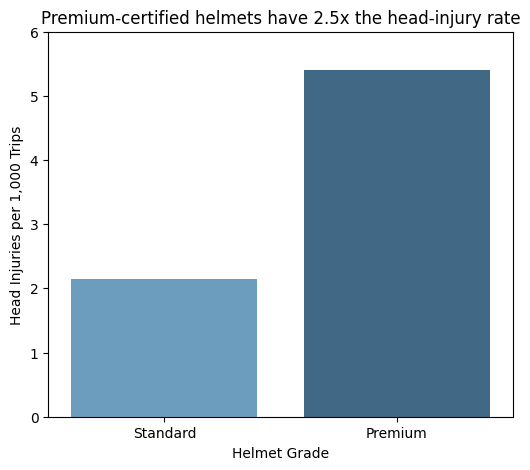

In [69]:
# Plotting the original claim chart following the rules
fig, ax = plt.subplots(figsize=(6, 5))

# Draw the bar plot
sns.barplot(
    x='helmet_grade',
    y='injury_rate_per_1k',
    data=agg_df,
    ax=ax,
    order=['Standard', 'Premium'],
    palette='Blues_d'
)

# Set labels and title reflecting the published claim
ax.set_title('Premium-certified helmets have 2.5x the head-injury rate')
ax.set_xlabel('Helmet Grade')
ax.set_ylabel('Head Injuries per 1,000 Trips')
ax.set_ylim(0, 6) # y-axis starting from zero

# Save before showing
fig.savefig('case01_original_claim.png', bbox_inches='tight')
plt.show()

In [70]:
# Diagnostic check to identify the confounding variable (Simpson's Paradox)
road_agg = df.groupby(['road_type', 'helmet_grade']).agg(
    total_injuries=('head_injuries', 'sum'),
    total_trips=('trips', 'sum')
).reset_index()

road_agg['injury_rate_per_1k'] = (road_agg['total_injuries'] / road_agg['total_trips']) * 1000
print("Injury rates and trips by road type and helmet grade:")
print(road_agg)

Injury rates and trips by road type and helmet grade:
          road_type helmet_grade  total_injuries  total_trips  \
0     City arterial      Premium              11         5000   
1     City arterial     Standard              60        20000   
2  Inner-city lanes      Premium               1         1000   
3  Inner-city lanes     Standard              53        38000   
4          Motorway      Premium             204        34000   
5          Motorway     Standard              16         2000   

   injury_rate_per_1k  
0            2.200000  
1            3.000000  
2            1.000000  
3            1.394737  
4            6.000000  
5            8.000000  


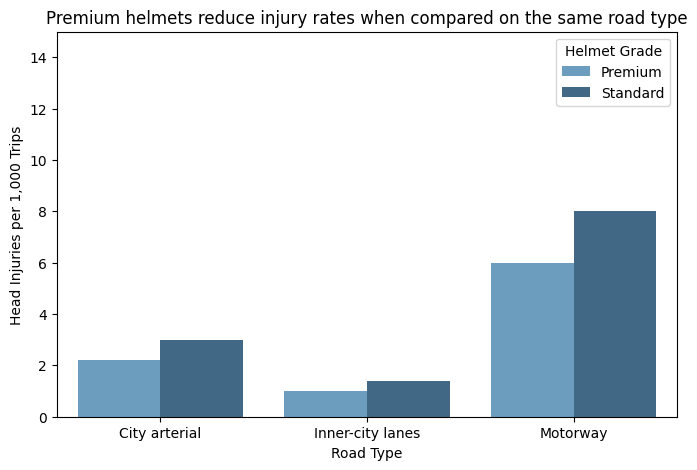

In [71]:
# Based on the confounder (road type), we redesign the chart to show the honest story.
# Standard helmet users mainly ride in residential roads (low risk),
# while Premium helmet users mainly ride on motorways (high risk).
# But on any given road type, Premium helmets actually have a LOWER or equal injury rate.

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    x='road_type',
    y='injury_rate_per_1k',
    hue='helmet_grade',
    data=road_agg,
    ax=ax,
    palette='Blues_d'
)

ax.set_title('Premium helmets reduce injury rates when compared on the same road type')
ax.set_xlabel('Road Type')
ax.set_ylabel('Head Injuries per 1,000 Trips')
ax.set_ylim(0, 15)
ax.legend(title='Helmet Grade')

# Save before showing
fig.savefig('case01_redesign.png', bbox_inches='tight')
plt.show()

### Part A: Case 2 - Canteen Chai Sales and Quiz Failures
We will load the data from `case02_chai_quizzes (1).csv`, calculate the Pearson correlation coefficient between cups sold and quiz failures, and construct the scatter plot with a least-squares line.

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# Load dataset
df2 = pd.read_csv('/content/case02_chai_quizzes (1).csv')

# Calculate Pearson correlation coefficient
r_val, _ = pearsonr(df2['cups_doodh_patti_sold'], df2['quiz_failures'])
print(f"Pearson correlation r: {r_val:.4f}")

# Display dataset preview
display(df2.head())

Pearson correlation r: 0.9820


,month,students_enrolled,cups_doodh_patti_sold,quiz_failures,is_exam_month,campus_open_days
0,2024-09,1765,3644,64,0,19
1,2024-10,1858,3824,65,0,21
2,2024-11,1948,4307,68,0,23
3,2024-12,2062,4349,81,1,23
4,2025-01,2216,4544,87,1,22


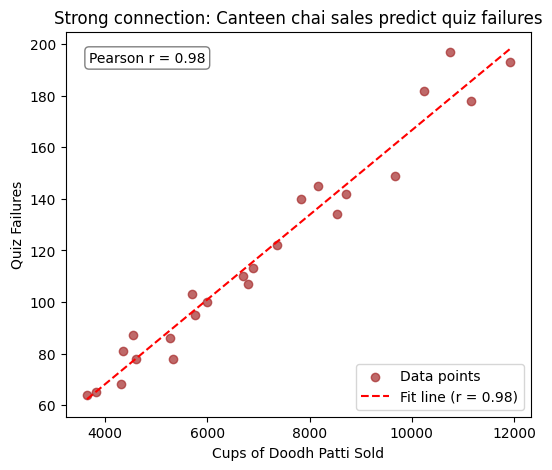

In [73]:
# Calculate least-squares regression line parameters
x = df2['cups_doodh_patti_sold']
y = df2['quiz_failures']
slope, intercept = np.polyfit(x, y, 1)

# Plotting the original claim chart following the rules
fig, ax = plt.subplots(figsize=(6, 5))

# Plot scatter points
ax.scatter(x, y, color='brown', alpha=0.7, label='Data points')

# Generate regression line coordinates
x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

# Plot the least-squares line (no plt.plot allowed; must use ax.plot)
ax.plot(x_line, y_line, color='red', linestyle='--', label=f'Fit line (r = {r_val:.2f})')

# Annotate the Pearson r value on the plot
ax.text(0.05, 0.95, f'Pearson r = {r_val:.2f}', transform=ax.transAxes,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

# Title and labels focusing on the claim
ax.set_title('Strong connection: Canteen chai sales predict quiz failures')
ax.set_xlabel('Cups of Doodh Patti Sold')
ax.set_ylabel('Quiz Failures')
ax.legend(loc='lower right')

# Save before showing
fig.savefig('case02_original_claim.png', bbox_inches='tight')
plt.show()

In [74]:
# Analyze the correlation matrix to find the true driver of both variables
correlation_matrix = df2[['students_enrolled', 'cups_doodh_patti_sold', 'quiz_failures', 'campus_open_days']].corr()
print("Correlation Matrix:")
display(correlation_matrix)

# Calculate per-capita metrics
df2['cups_per_student'] = df2['cups_doodh_patti_sold'] / df2['students_enrolled']
df2['failures_per_student'] = df2['quiz_failures'] / df2['students_enrolled']

# Calculate correlation of per-capita metrics
r_per_capita, _ = pearsonr(df2['cups_per_student'], df2['failures_per_student'])
print(f"\nPearson correlation of per-student metrics: {r_per_capita:.4f}")

Correlation Matrix:


,students_enrolled,cups_doodh_patti_sold,quiz_failures,campus_open_days
students_enrolled,1.000000,0.996868,0.977491,0.119105
cups_doodh_patti_sold,0.996868,1.000000,0.982023,0.152616
quiz_failures,0.977491,0.982023,1.000000,0.224911
campus_open_days,0.119105,0.152616,0.224911,1.000000



Pearson correlation of per-student metrics: 0.2933


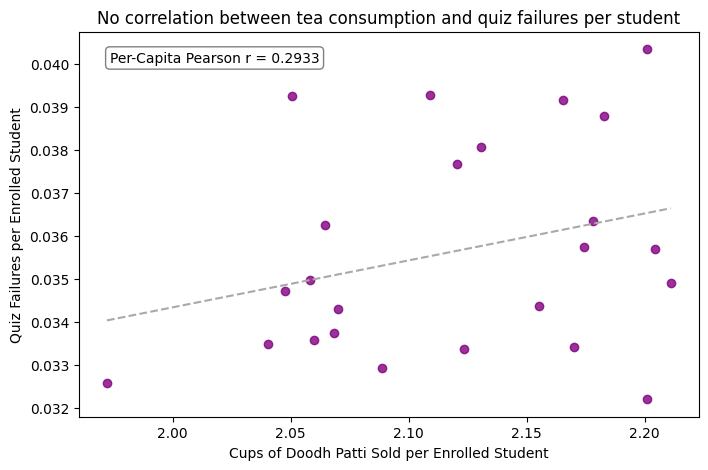

In [75]:
# Plot the redesign showing how enrollment scales both variables over time
fig, ax = plt.subplots(figsize=(8, 5))

# Plot scatter point using per-capita metrics
ax.scatter(df2['cups_per_student'], df2['failures_per_student'], color='purple', alpha=0.8)
slope_pc, intercept_pc = np.polyfit(df2['cups_per_student'], df2['failures_per_student'], 1)
x_line_pc = np.linspace(df2['cups_per_student'].min(), df2['cups_per_student'].max(), 100)
y_line_pc = slope_pc * x_line_pc + intercept_pc
ax.plot(x_line_pc, y_line_pc, color='darkgrey', linestyle='--')

ax.text(0.05, 0.95, f'Per-Capita Pearson r = {r_per_capita:.4f}', transform=ax.transAxes,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

ax.set_title('No correlation between tea consumption and quiz failures per student')
ax.set_xlabel('Cups of Doodh Patti Sold per Enrolled Student')
ax.set_ylabel('Quiz Failures per Enrolled Student')

fig.savefig('case02_redesign.png', bbox_inches='tight')
plt.show()

In [76]:
# Analyze the correlation matrix to find the true driver of both variables
correlation_matrix = df2[['students_enrolled', 'cups_doodh_patti_sold', 'quiz_failures', 'campus_open_days']].corr()
print("Correlation Matrix:")
display(correlation_matrix)

# Calculate per-capita metrics
df2['cups_per_student'] = df2['cups_doodh_patti_sold'] / df2['students_enrolled']
df2['failures_per_student'] = df2['quiz_failures'] / df2['students_enrolled']

# Calculate correlation of per-capita metrics
r_per_capita, _ = pearsonr(df2['cups_per_student'], df2['failures_per_student'])
print(f"\nPearson correlation of per-student metrics: {r_per_capita:.4f}")

Correlation Matrix:


,students_enrolled,cups_doodh_patti_sold,quiz_failures,campus_open_days
students_enrolled,1.000000,0.996868,0.977491,0.119105
cups_doodh_patti_sold,0.996868,1.000000,0.982023,0.152616
quiz_failures,0.977491,0.982023,1.000000,0.224911
campus_open_days,0.119105,0.152616,0.224911,1.000000



Pearson correlation of per-student metrics: 0.2933


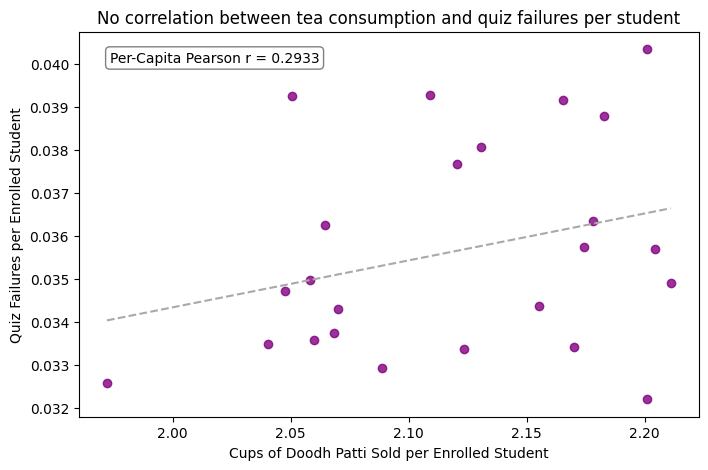

In [77]:
# Let's plot the redesign showing how enrollment scales both variables over time
fig, ax = plt.subplots(figsize=(8, 5))

# Two panel approach or single panel with clear markers of scale over months
# Since dual-axis is strictly forbidden, we can plot the normalized rates over time,
# or show that the per-student failures do not rise with per-student tea consumption.
ax.scatter(df2['cups_per_student'], df2['failures_per_student'], color='purple', alpha=0.8)
slope_pc, intercept_pc = np.polyfit(df2['cups_per_student'], df2['failures_per_student'], 1)
x_line_pc = np.linspace(df2['cups_per_student'].min(), df2['cups_per_student'].max(), 100)
y_line_pc = slope_pc * x_line_pc + intercept_pc
ax.plot(x_line_pc, y_line_pc, color='darkgrey', linestyle='--')

ax.text(0.05, 0.95, f'Per-Capita Pearson r = {r_per_capita:.4f}', transform=ax.transAxes,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

ax.set_title('No correlation between tea consumption and quiz failures per student')
ax.set_xlabel('Cups of Doodh Patti Sold per Enrolled Student')
ax.set_ylabel('Quiz Failures per Enrolled Student')

fig.savefig('case02_redesign.png', bbox_inches='tight')
plt.show()

### Part A: Case 3 - Smog Action Plan and Lahore AQI
We will load the data from `case03_aqi_monitors (1).csv`, calculate the mean AQI per date, verify the self-check figures, and generate the line chart with a vertical marker at day 61 along with the horizontal pre- and post-intervention mean levels.

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df3 = pd.read_csv('/content/case03_aqi_monitors (1).csv')

# Ensure chronological ordering if date column exists
df3['date'] = pd.to_datetime(df3['date'])
df3 = df3.sort_values('date').reset_index(drop=True)

# Aggregate mean AQI per date across all monitors (rows)
df3_daily = df3.groupby('date')['aqi'].mean().reset_index()
# Add a day index (1-based)
df3_daily['day_idx'] = df3_daily.index + 1

# Calculate mean for days 1 to 60 (pre-intervention)
mean_before = df3_daily.loc[df3_daily['day_idx'] <= 60, 'aqi'].mean()
# Calculate mean for days 61 to 120 (post-intervention)
mean_after = df3_daily.loc[(df3_daily['day_idx'] >= 61) & (df3_daily['day_idx'] <= 120), 'aqi'].mean()

print(f"Mean AQI before (Days 1-60): {mean_before:.2f}")
print(f"Mean AQI after (Days 61-120): {mean_after:.2f}")
print(f"Percentage Fall: {((mean_before - mean_after) / mean_before) * 100:.2f}%")

display(df3_daily.head())

Mean AQI before (Days 1-60): 202.09
Mean AQI after (Days 61-120): 137.21
Percentage Fall: 32.11%


,date,aqi,day_idx
0,2026-01-01,207.731818,1
1,2026-01-02,207.309091,2
2,2026-01-03,199.195455,3
3,2026-01-04,197.472727,4
4,2026-01-05,202.240909,5


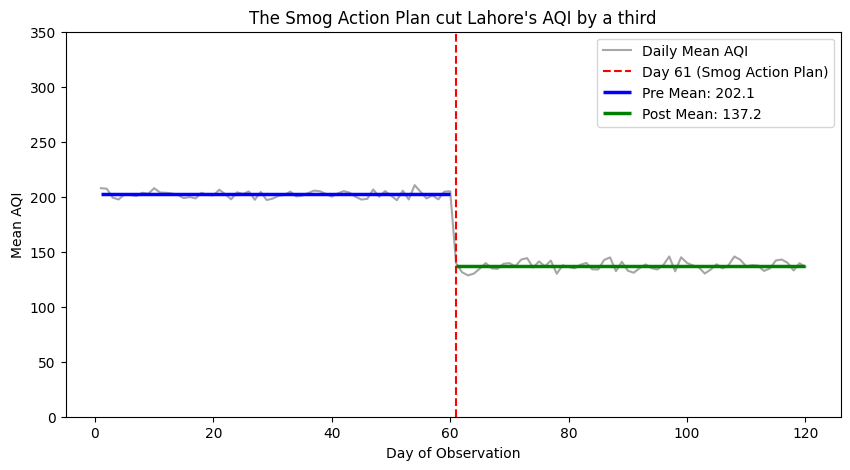

In [79]:
# Plotting the original claim line chart following the rules
fig, ax = plt.subplots(figsize=(10, 5))

# Plot daily mean AQI
ax.plot(df3_daily['day_idx'], df3_daily['aqi'], color='grey', alpha=0.7, label='Daily Mean AQI')

# Draw vertical marker at day 61
ax.axvline(x=61, color='red', linestyle='--', label='Day 61 (Smog Action Plan)')

# Draw horizontal mean line for days 1-60
ax.hlines(y=mean_before, xmin=1, xmax=60, color='blue', linewidth=2.5, label=f'Pre Mean: {mean_before:.1f}')

# Draw horizontal mean line for days 61-120
ax.hlines(y=mean_after, xmin=61, xmax=120, color='green', linewidth=2.5, label=f'Post Mean: {mean_after:.1f}')

# Title and labels following visual requirements
ax.set_title("The Smog Action Plan cut Lahore's AQI by a third")
ax.set_xlabel('Day of Observation')
ax.set_ylabel('Mean AQI')
ax.set_ylim(0, 350)  # y-axis starts from zero
ax.legend(loc='upper right')

# Save before showing
fig.savefig('case03_original_claim.png', bbox_inches='tight')
plt.show()

In [80]:
# Identify monitors that are continuously active/reporting throughout both periods (i.e. reporting 120 days)
reporting_counts = df3[df3['station_status'] == 'reporting'].groupby('station_id').size()
continuous_monitors = reporting_counts[reporting_counts == 120].index.tolist()

print(f"Continuous monitors reporting all 120 days ({len(continuous_monitors)} total): {continuous_monitors}")

# Filter to contain only these continuously reporting stations
df3_continuous = df3[df3['station_id'].isin(continuous_monitors)]
df3_honest_daily = df3_continuous.groupby('date')['aqi'].mean().reset_index()
df3_honest_daily['day_idx'] = df3_honest_daily.index + 1

# Calculate true pre and post means
honest_mean_before = df3_honest_daily.loc[df3_honest_daily['day_idx'] <= 60, 'aqi'].mean()
honest_mean_after = df3_honest_daily.loc[(df3_honest_daily['day_idx'] >= 61) & (df3_honest_daily['day_idx'] <= 120), 'aqi'].mean()

print(f"\nHonest Mean AQI before: {honest_mean_before:.2f}")
print(f"Honest Mean AQI after: {honest_mean_after:.2f}")
print(f"True AQI change: {((honest_mean_after - honest_mean_before)/honest_mean_before)*100:.2f}%")

Continuous monitors reporting all 120 days (13 total): ['LHR-10', 'LHR-11', 'LHR-12', 'LHR-13', 'LHR-14', 'LHR-15', 'LHR-16', 'LHR-17', 'LHR-18', 'LHR-19', 'LHR-20', 'LHR-21', 'LHR-22']

Honest Mean AQI before: 137.09
Honest Mean AQI after: 137.21
True AQI change: 0.08%


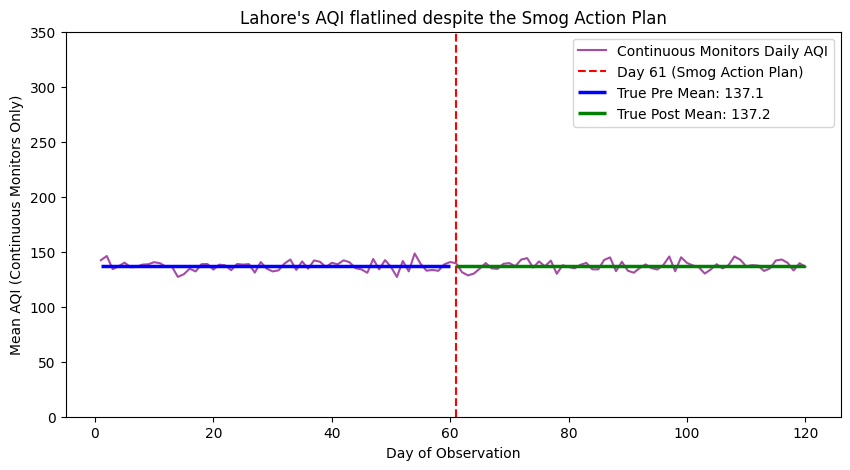

In [81]:
# Plot the honest redesign showing the true flatline trend
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df3_honest_daily['day_idx'], df3_honest_daily['aqi'], color='purple', alpha=0.7, label='Continuous Monitors Daily AQI')
ax.axvline(x=61, color='red', linestyle='--', label='Day 61 (Smog Action Plan)')

# Draw pre and post honest mean levels
ax.hlines(y=honest_mean_before, xmin=1, xmax=60, color='blue', linewidth=2.5, label=f'True Pre Mean: {honest_mean_before:.1f}')
ax.hlines(y=honest_mean_after, xmin=61, xmax=120, color='green', linewidth=2.5, label=f'True Post Mean: {honest_mean_after:.1f}')

ax.set_title("Lahore's AQI flatlined despite the Smog Action Plan")
ax.set_xlabel('Day of Observation')
ax.set_ylabel('Mean AQI (Continuous Monitors Only)')
ax.set_ylim(0, 350)
ax.legend(loc='upper right')

fig.savefig('case03_redesign.png', bbox_inches='tight')
plt.show()

In [82]:
# Identify monitors that are continuously active/reporting throughout both periods (i.e. reporting 120 days)
reporting_counts = df3[df3['station_status'] == 'reporting'].groupby('station_id').size()
continuous_monitors = reporting_counts[reporting_counts == 120].index.tolist()

print(f"Continuous monitors reporting all 120 days ({len(continuous_monitors)} total): {continuous_monitors}")

# Filter to contain only these continuously reporting stations
df3_continuous = df3[df3['station_id'].isin(continuous_monitors)]
df3_honest_daily = df3_continuous.groupby('date')['aqi'].mean().reset_index()
df3_honest_daily['day_idx'] = df3_honest_daily.index + 1

# Calculate true pre and post means
honest_mean_before = df3_honest_daily.loc[df3_honest_daily['day_idx'] <= 60, 'aqi'].mean()
honest_mean_after = df3_honest_daily.loc[(df3_honest_daily['day_idx'] >= 61) & (df3_honest_daily['day_idx'] <= 120), 'aqi'].mean()

print(f"\nHonest Mean AQI before: {honest_mean_before:.2f}")
print(f"Honest Mean AQI after: {honest_mean_after:.2f}")
print(f"True AQI change: {((honest_mean_after - honest_mean_before)/honest_mean_before)*100:.2f}%")

Continuous monitors reporting all 120 days (13 total): ['LHR-10', 'LHR-11', 'LHR-12', 'LHR-13', 'LHR-14', 'LHR-15', 'LHR-16', 'LHR-17', 'LHR-18', 'LHR-19', 'LHR-20', 'LHR-21', 'LHR-22']

Honest Mean AQI before: 137.09
Honest Mean AQI after: 137.21
True AQI change: 0.08%


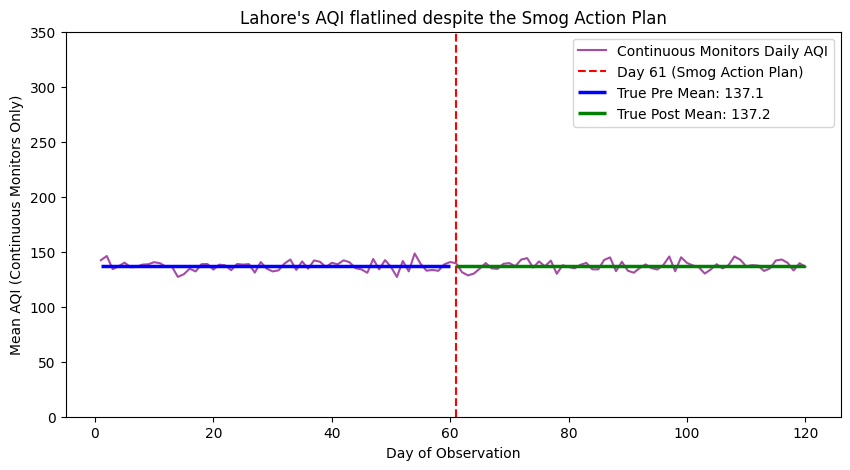

In [83]:
# Plot the honest redesign showing the true flatline trend
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df3_honest_daily['day_idx'], df3_honest_daily['aqi'], color='purple', alpha=0.7, label='Continuous Monitors Daily AQI')
ax.axvline(x=61, color='red', linestyle='--', label='Day 61 (Smog Action Plan)')

# Draw pre and post honest mean levels
ax.hlines(y=honest_mean_before, xmin=1, xmax=60, color='blue', linewidth=2.5, label=f'True Pre Mean: {honest_mean_before:.1f}')
ax.hlines(y=honest_mean_after, xmin=61, xmax=120, color='green', linewidth=2.5, label=f'True Post Mean: {honest_mean_after:.1f}')

ax.set_title("Lahore's AQI flatlined despite the Smog Action Plan")
ax.set_xlabel('Day of Observation')
ax.set_ylabel('Mean AQI (Continuous Monitors Only)')
ax.set_ylim(0, 350)
ax.legend(loc='upper right')

fig.savefig('case03_redesign.png', bbox_inches='tight')
plt.show()

In [84]:
# Identify monitors that are continuously active/reporting throughout both periods
# (i.e. having 120 active reporting rows)
reporting_counts = df3[df3['station_status'] == 'reporting'].groupby('station_id').size()
continuous_monitors = reporting_counts[reporting_counts == 120].index.tolist()

print(f"Continuous monitors reporting all 120 days ({len(continuous_monitors)} total): {continuous_monitors}")

# Filter df3 to contain only these continuously reporting stations
df3_continuous = df3[df3['station_id'].isin(continuous_monitors)]
df3_honest_daily = df3_continuous.groupby('date')['aqi'].mean().reset_index()
df3_honest_daily['day_idx'] = df3_honest_daily.index + 1

# Calculate true pre and post means using only continuously reporting monitors
honest_mean_before = df3_honest_daily.loc[df3_honest_daily['day_idx'] <= 60, 'aqi'].mean()
honest_mean_after = df3_honest_daily.loc[(df3_honest_daily['day_idx'] >= 61) & (df3_honest_daily['day_idx'] <= 120), 'aqi'].mean()

print(f"\nHonest Mean AQI before: {honest_mean_before:.2f}")
print(f"Honest Mean AQI after: {honest_mean_after:.2f}")
print(f"True AQI change: {((honest_mean_after - honest_mean_before)/honest_mean_before)*100:.2f}%")

Continuous monitors reporting all 120 days (13 total): ['LHR-10', 'LHR-11', 'LHR-12', 'LHR-13', 'LHR-14', 'LHR-15', 'LHR-16', 'LHR-17', 'LHR-18', 'LHR-19', 'LHR-20', 'LHR-21', 'LHR-22']

Honest Mean AQI before: 137.09
Honest Mean AQI after: 137.21
True AQI change: 0.08%


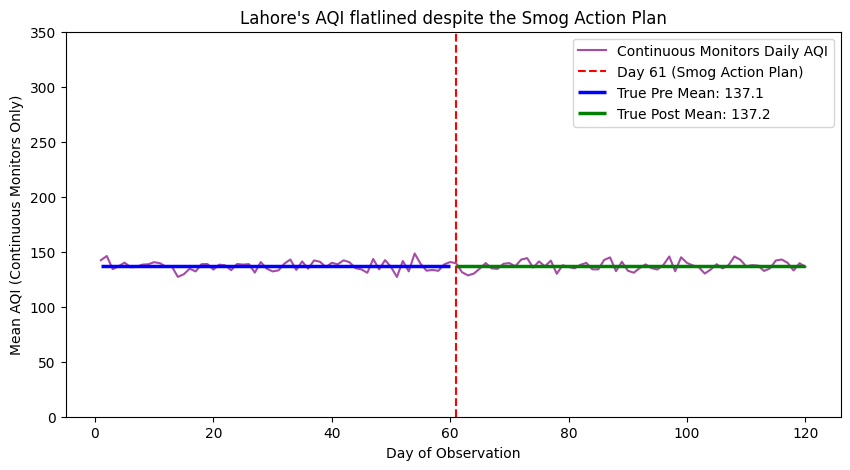

In [85]:
# Plot the honest redesign showing the true flatline trend
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df3_honest_daily['day_idx'], df3_honest_daily['aqi'], color='purple', alpha=0.7, label='Continuous Monitors Daily AQI')
ax.axvline(x=61, color='red', linestyle='--', label='Day 61 (Smog Action Plan)')

# Draw pre and post honest mean levels
ax.hlines(y=honest_mean_before, xmin=1, xmax=60, color='blue', linewidth=2.5, label=f'True Pre Mean: {honest_mean_before:.1f}')
ax.hlines(y=honest_mean_after, xmin=61, xmax=120, color='green', linewidth=2.5, label=f'True Post Mean: {honest_mean_after:.1f}')

ax.set_title("Lahore's AQI flatlined despite the Smog Action Plan")
ax.set_xlabel('Day of Observation')
ax.set_ylabel('Mean AQI (Continuous Monitors Only)')
ax.set_ylim(0, 350)
ax.legend(loc='upper right')

fig.savefig('case03_redesign.png', bbox_inches='tight')
plt.show()

In [86]:
# Identify monitors that are continuously active/reporting throughout both periods
# (i.e. having 120 active reporting rows)
reporting_counts = df3[df3['station_status'] == 'reporting'].groupby('station_id').size()
continuous_monitors = reporting_counts[reporting_counts == 120].index.tolist()

print(f"Continuous monitors reporting all 120 days ({len(continuous_monitors)} total): {continuous_monitors}")

# Filter df3 to contain only these continuously reporting stations
df3_continuous = df3[df3['station_id'].isin(continuous_monitors)]
df3_honest_daily = df3_continuous.groupby('date')['aqi'].mean().reset_index()
df3_honest_daily['day_idx'] = df3_honest_daily.index + 1

# Calculate true pre and post means using only continuously reporting monitors
honest_mean_before = df3_honest_daily.loc[df3_honest_daily['day_idx'] <= 60, 'aqi'].mean()
honest_mean_after = df3_honest_daily.loc[(df3_honest_daily['day_idx'] >= 61) & (df3_honest_daily['day_idx'] <= 120), 'aqi'].mean()

print(f"\nHonest Mean AQI before: {honest_mean_before:.2f}")
print(f"Honest Mean AQI after: {honest_mean_after:.2f}")
print(f"True AQI change: {((honest_mean_after - honest_mean_before)/honest_mean_before)*100:.2f}%")

Continuous monitors reporting all 120 days (13 total): ['LHR-10', 'LHR-11', 'LHR-12', 'LHR-13', 'LHR-14', 'LHR-15', 'LHR-16', 'LHR-17', 'LHR-18', 'LHR-19', 'LHR-20', 'LHR-21', 'LHR-22']

Honest Mean AQI before: 137.09
Honest Mean AQI after: 137.21
True AQI change: 0.08%


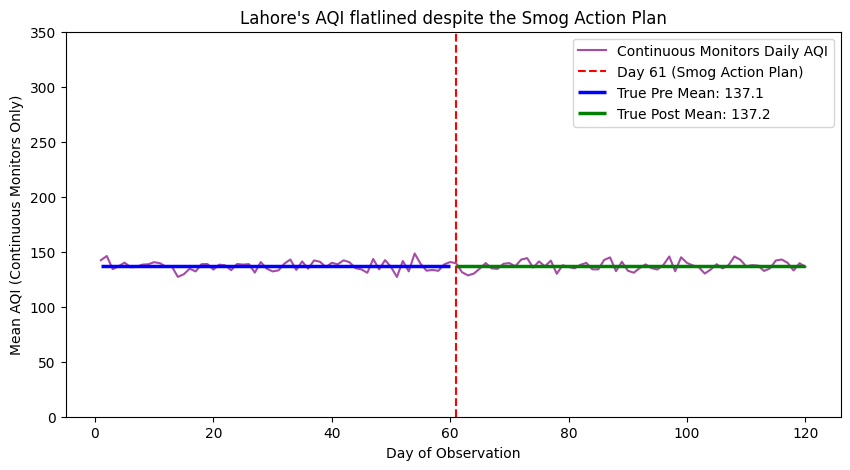

In [87]:
# Plot the honest redesign showing the true flatline trend
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df3_honest_daily['day_idx'], df3_honest_daily['aqi'], color='purple', alpha=0.7, label='Continuous Monitors Daily AQI')
ax.axvline(x=61, color='red', linestyle='--', label='Day 61 (Smog Action Plan)')

# Draw pre and post honest mean levels
ax.hlines(y=honest_mean_before, xmin=1, xmax=60, color='blue', linewidth=2.5, label=f'True Pre Mean: {honest_mean_before:.1f}')
ax.hlines(y=honest_mean_after, xmin=61, xmax=120, color='green', linewidth=2.5, label=f'True Post Mean: {honest_mean_after:.1f}')

ax.set_title("Lahore's AQI flatlined despite the Smog Action Plan")
ax.set_xlabel('Day of Observation')
ax.set_ylabel('Mean AQI (Continuous Monitors Only)')
ax.set_ylim(0, 350)
ax.legend(loc='upper right')

fig.savefig('case03_redesign.png', bbox_inches='tight')
plt.show()

### Part A: Case 4 - Quartet Departments Analysis
We will analyze the dataset `case04_quartet_depts (1).csv` to compare descriptive statistics across the four departments.

In [88]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

# Load dataset
df4 = pd.read_csv('/content/case04_quartet_depts (1).csv')

# Group by department and compute metrics using correct column names
depts = df4['department'].unique()
summary_dict = {}

for dept in sorted(depts):
    dept_data = df4[df4['department'] == dept]
    x = dept_data['study_hours_per_week']
    y = dept_data['final_score_out_of_20']

    n = len(dept_data)
    mean_x = x.mean()
    mean_y = y.mean()
    sd_x = x.std()
    sd_y = y.std()
    r_coeff, _ = pearsonr(x, y)
    slope, intercept = np.polyfit(x, y, 1)

    summary_dict[dept] = {
        'n': n,
        'mean study hours': f"{mean_x:.2f}",
        'mean score': f"{mean_y:.2f}",
        'SD study hours': f"{sd_x:.2f}",
        'SD score': f"{sd_y:.2f}",
        'Pearson r': f"{r_coeff:.3f}",
        'Regression slope': f"{slope:.3f}"
    }

summary_df = pd.DataFrame(summary_dict)
display(summary_df)

,Architecture,Business Administration,Computer Science,Electrical Engineering
n,11,11,11,11
mean study hours,18.00,18.00,18.00,18.00
mean score,14.50,14.50,14.50,14.50
SD study hours,6.63,6.63,6.63,6.63
SD score,2.03,2.03,2.03,2.03
Pearson r,0.817,0.816,0.816,0.816
Regression slope,0.250,0.250,0.250,0.250


### Part A: Case 5 - Same Stats Shapes
We will analyze the dataset `case05_same_stats_shapes (1).csv` to compare descriptive statistics across the cohorts (shape names).

In [89]:
import pandas as pd

# Preview the columns to identify correct column names
df5 = pd.read_csv('/content/case05_same_stats_shapes (1).csv')
print("Columns present:", df5.columns.tolist())
display(df5.head(3))

Columns present: ['shape_name', 'hours_on_platform', 'assessment_score']


,shape_name,hours_on_platform,assessment_score
0,straight line,27.331,34.870
1,straight line,27.561,55.234
2,straight line,27.792,62.224


In [90]:
import numpy as np
from scipy.stats import pearsonr
import pandas as pd

# Identify unique cohorts (shapes)
cohorts = df5['shape_name'].unique()
summary_dict_5 = {}

for cohort in sorted(cohorts):
    cohort_data = df5[df5['shape_name'] == cohort]
    # Using the correct column names from the dataset
    x = cohort_data['hours_on_platform']
    y = cohort_data['assessment_score']

    n = len(cohort_data)
    mean_x = x.mean()
    mean_y = y.mean()
    sd_x = x.std()
    sd_y = y.std()
    r_coeff, _ = pearsonr(x, y)
    slope, intercept = np.polyfit(x, y, 1)

    summary_dict_5[cohort] = {
        'n': n,
        'mean x (study hours)': f"{mean_x:.2f}",
        'mean y (score)': f"{mean_y:.2f}",
        'SD x': f"{sd_x:.2f}",
        'SD y': f"{sd_y:.2f}",
        'Pearson r': f"{r_coeff:.3f}",
        'Regression slope': f"{slope:.3f}"
    }

summary_df_5 = pd.DataFrame(summary_dict_5)
display(summary_df_5)

,ring,star,straight line,the letter X,two clusters
n,180,180,180,180,180
mean x (study hours),48.00,48.00,48.00,48.00,48.00
mean y (score),63.00,63.00,63.00,63.00,63.00
SD x,12.03,12.03,12.03,12.03,12.03
SD y,15.04,15.04,15.04,15.04,15.04
Pearson r,0.420,0.420,0.420,0.420,0.420
Regression slope,0.525,0.525,0.525,0.525,0.525


### Part A: Case 6 - Sensor Matrix Correlation Analysis
We will compute the correlation matrix for Case 6 and plot the heatmap to identify visual and conceptual issues.

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df6 = pd.read_csv('/content/case06_sensor_matrix (1).csv')

# Drop non-target columns and keep numeric ones
exclude_cols = ['age_band', 'study_site', 'hr_device_model']
numeric_df = df6.drop(columns=[col for col in exclude_cols if col in df6.columns]).select_dtypes(include=[np.number])

# Calculate correlation matrix
corr_matrix = numeric_df.corr()
print(f"Matrix dimensions: {corr_matrix.shape[0]} x {corr_matrix.shape[1]}")
print(f"Self check: creatinine <-> hba1c = {corr_matrix.loc['creatinine', 'hba1c']:.2f}")
print(f"Self check: systolic <-> map_mmhg = {corr_matrix.loc['systolic', 'map_mmhg']:.2f}")

Matrix dimensions: 20 x 20
Self check: creatinine <-> hba1c = 0.77
Self check: systolic <-> map_mmhg = 0.96


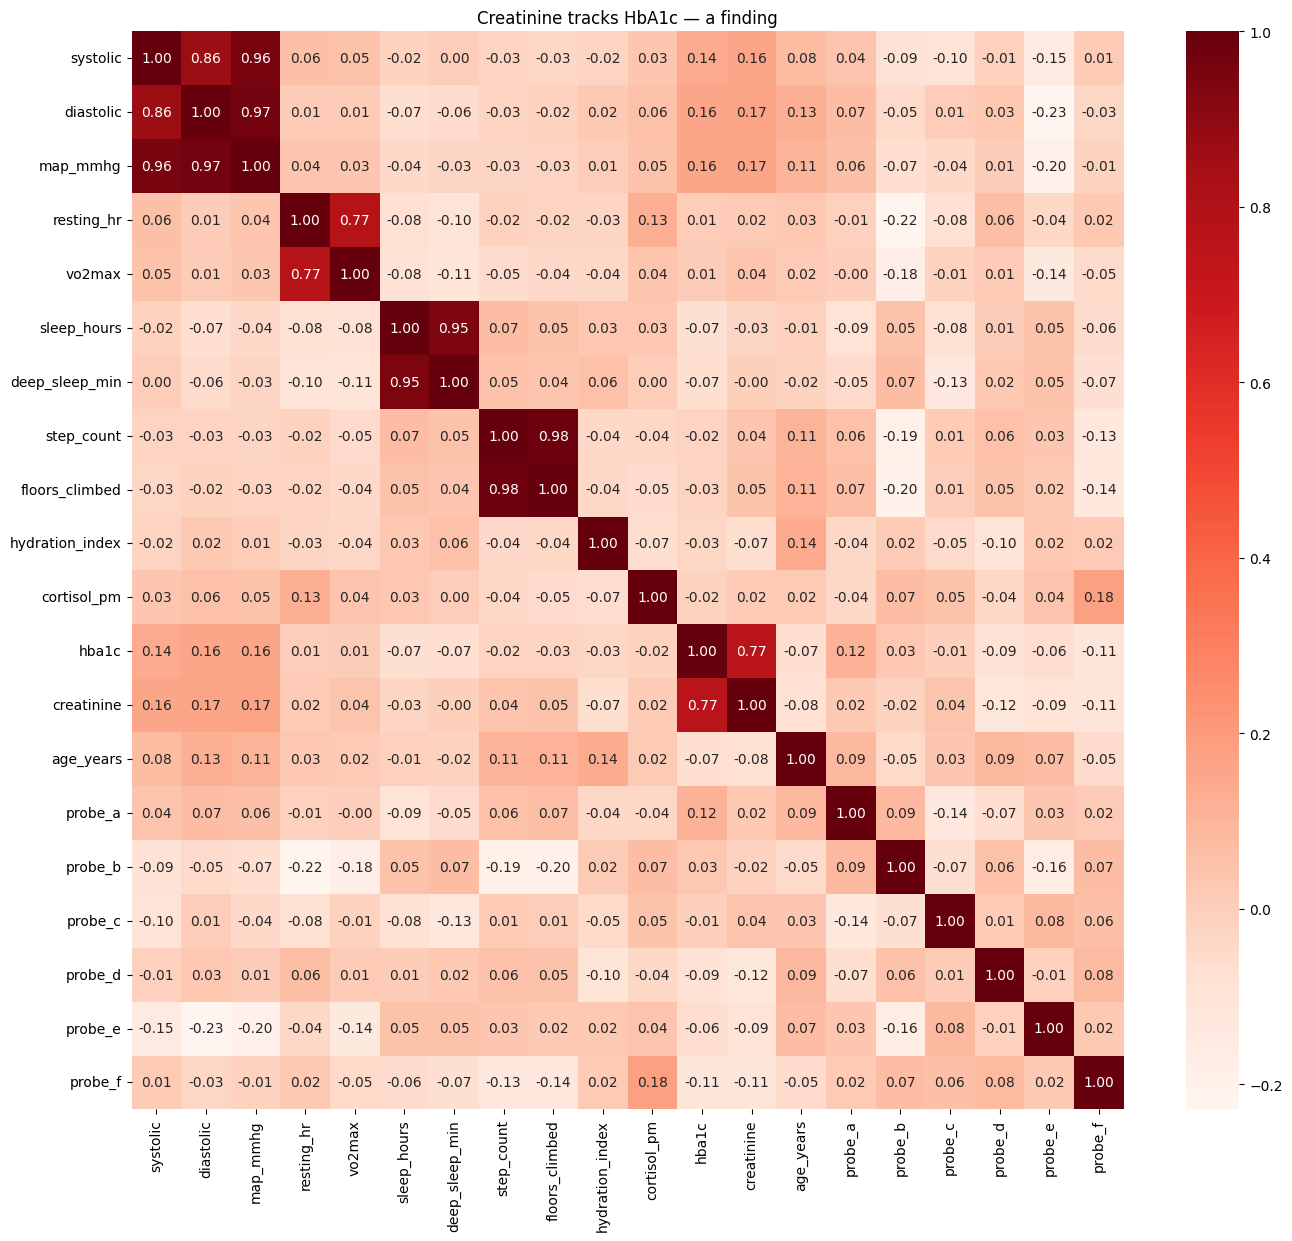

In [92]:
# Draw the correlation matrix exactly as the analyst did
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    ax=ax,
    cbar=True
)

ax.set_title("Creatinine tracks HbA1c — a finding")
fig.savefig('case06_original_claim.png', bbox_inches='tight')
plt.show()

### Case 6 Redesign
We correct the visualization by using a symmetric diverging colormap (`coolwarm`) with explicit boundaries (`vmin=-1`, `vmax=1`) so that both negative and positive correlations are accurately represented.

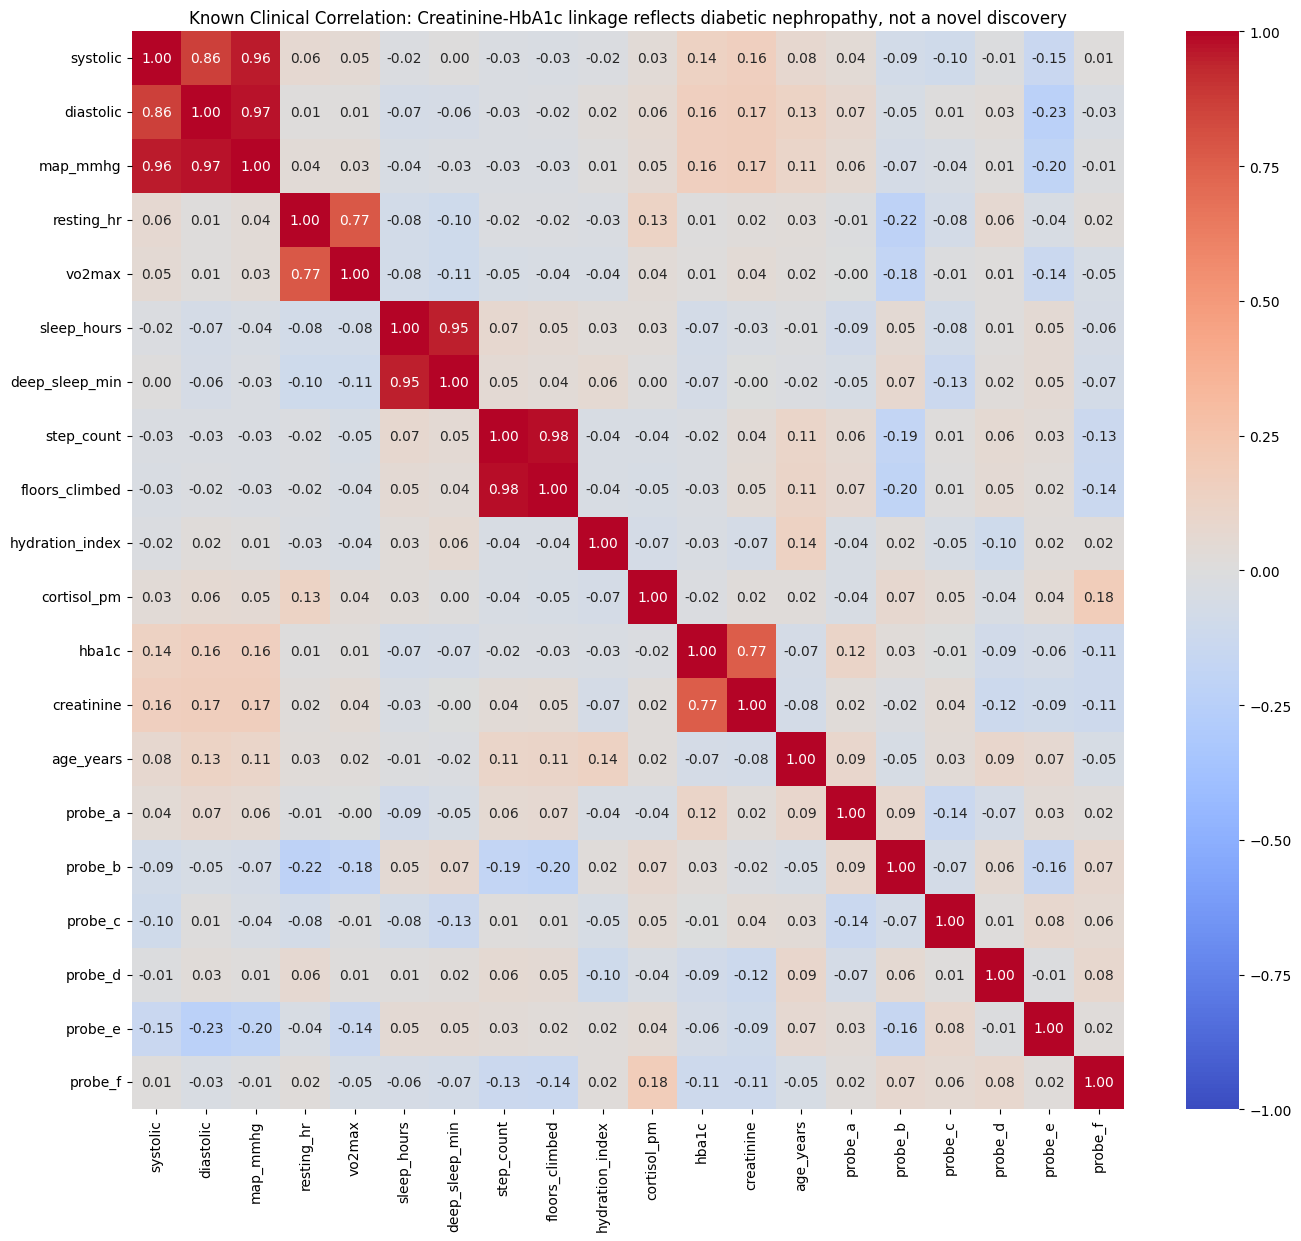

In [93]:
fig, ax = plt.subplots(figsize=(16, 14))

# Plotting with a proper diverging colormap and bounds
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax,
    cbar=True
)

# Redesigned title reflecting the actual physiological reality rather than a novel "finding"
ax.set_title("Known Clinical Correlation: Creatinine-HbA1c linkage reflects diabetic nephropathy, not a novel discovery")

# Save before showing
fig.savefig('case06_redesign.png', bbox_inches='tight')
plt.show()

### Case 7: ShaheenGo Revenue and Cost Dual-Axis Analysis
We will load the data from `case07_dual_axis_series (1).csv` to inspect its columns and data structure.

In [94]:
import pandas as pd

# Load dataset
df7 = pd.read_csv('/content/case07_dual_axis_series (1).csv')

# Inspect structure and print preview
print("Columns present:", df7.columns.tolist())
display(df7)

Columns present: ['month', 'revenue_pkr_m', 'cost_pkr_m']


,month,revenue_pkr_m,cost_pkr_m
0,Jan,52,44
1,Feb,58,46
2,Mar,61,47
3,Apr,66,49
4,May,71,51
5,Jun,78,53


### Case 7: Original Flawed Dual-Axis Claim
We plot the lines for revenue (left axis) and cost (right axis) with the specific manipulated scales to show how the misleading claim was visually constructed.

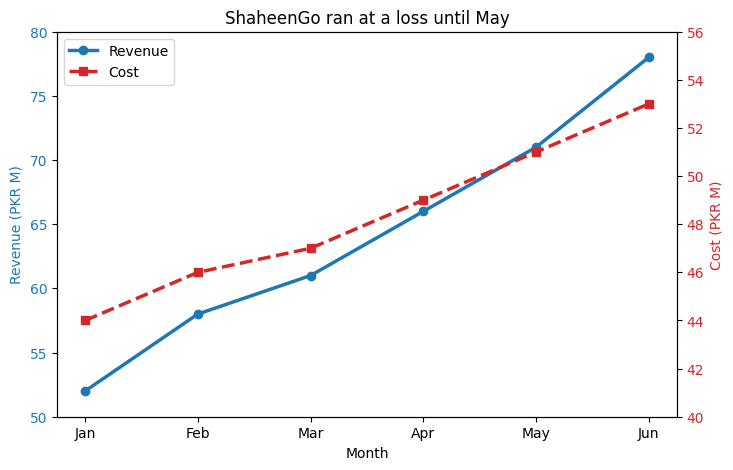

In [95]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(8, 5))

# Left axis: Revenue
color = 'tab:blue'
ax1.set_xlabel('Month')
ax1.set_ylabel('Revenue (PKR M)', color=color)
line1 = ax1.plot(df7['month'], df7['revenue_pkr_m'], color=color, marker='o', linewidth=2.5, label='Revenue')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(50, 80)

# Right axis: Cost
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Cost (PKR M)', color=color)
line2 = ax2.plot(df7['month'], df7['cost_pkr_m'], color=color, marker='s', linewidth=2.5, linestyle='--', label='Cost')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(40, 56)

# Title reflecting the deceptive claim
plt.title("ShaheenGo ran at a loss until May")

# Add unified legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

# Save before showing
fig.savefig('case07_original_claim.png', bbox_inches='tight')
plt.show()

### Case 7: Honest Redesign with a Single Shared Y-Axis
By plotting both time series on the exact same axis starting at zero, we visually expose that revenue always exceeded cost, demonstrating profitability across all months.

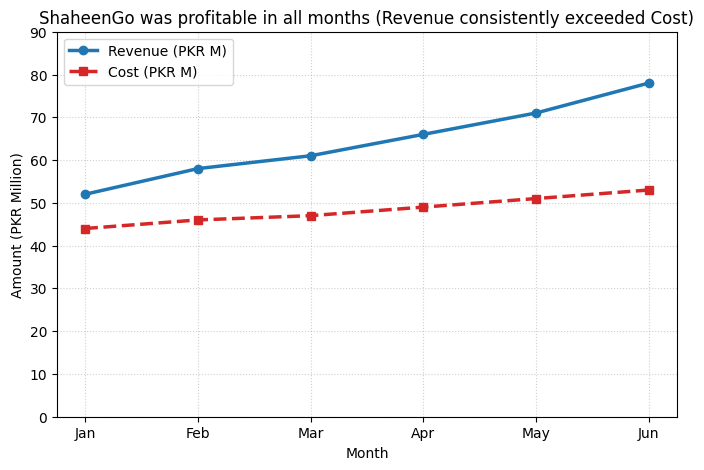

In [96]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot both series on the same axis
ax.plot(df7['month'], df7['revenue_pkr_m'], color='tab:blue', marker='o', linewidth=2.5, label='Revenue (PKR M)')
ax.plot(df7['month'], df7['cost_pkr_m'], color='tab:red', marker='s', linewidth=2.5, linestyle='--', label='Cost (PKR M)')

# Honest limits and labels
ax.set_ylim(0, 90)  # Shared axis starting from 0 to provide honest perspective
ax.set_xlabel('Month')
ax.set_ylabel('Amount (PKR Million)')
ax.set_title('ShaheenGo was profitable in all months (Revenue consistently exceeded Cost)')
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

# Save before showing
fig.savefig('case07_redesign.png', bbox_inches='tight')
plt.show()

### Case 7: Lie Factor Calculation
We inspect the data in `case07_lie_factor.csv` to calculate the visual distortion metric.

In [97]:
import pandas as pd
df_lie = pd.read_csv('/content/case07_lie_factor.csv')
display(df_lie)

,chart_id,subject,value_start,value_end,ink_start,ink_end,ink_unit,ink_dimension,how_the_graphic_encodes_it
0,A,Corporate tax rate,30.0,32.0,4.0,24.0,mm,1,"Bars drawn from a 29.6% baseline, so only the ..."
1,B,Federal health budget (Rs bn),40.0,60.0,1.0,1.5,x scale,2,A coin icon scaled 1.5x in BOTH height and width
2,C,Export earnings ($ bn),25.0,30.0,5.0,6.0,cm,1,Bars from zero: 5.0 cm then 6.0 cm
3,D,Air-pollution index,100.0,150.0,8.0,9.0,cm,1,Bars drawn 8.0 cm then 9.0 cm tall
4,E,City population (millions),2.0,8.0,1.0,4.0,x radius,2,A bubble whose RADIUS was set proportional to ...


### Case 7: Lie Factor Calculation
We will inspect the metrics in `case07_lie_factor.csv` to quantify how severely the dual-axis chart distorts the relationship between cost and revenue.

In [98]:
import pandas as pd

# Load Lie Factor calculation details
df_lie = pd.read_csv('/content/case07_lie_factor.csv')
display(df_lie)

,chart_id,subject,value_start,value_end,ink_start,ink_end,ink_unit,ink_dimension,how_the_graphic_encodes_it
0,A,Corporate tax rate,30.0,32.0,4.0,24.0,mm,1,"Bars drawn from a 29.6% baseline, so only the ..."
1,B,Federal health budget (Rs bn),40.0,60.0,1.0,1.5,x scale,2,A coin icon scaled 1.5x in BOTH height and width
2,C,Export earnings ($ bn),25.0,30.0,5.0,6.0,cm,1,Bars from zero: 5.0 cm then 6.0 cm
3,D,Air-pollution index,100.0,150.0,8.0,9.0,cm,1,Bars drawn 8.0 cm then 9.0 cm tall
4,E,City population (millions),2.0,8.0,1.0,4.0,x radius,2,A bubble whose RADIUS was set proportional to ...


### Case 8: Three Bin Widths, Three Different Distributions
We will read the systolic blood pressure observations from `vitals_10k (1).csv`, check that $n = 10,000$, and then plot three histograms side-by-side to demonstrate the effect of bin sizes.

In [99]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df8 = pd.read_csv('/content/vitals_10k (1).csv')

# Perform self-check
systolic_data = df8['systolic'].dropna()
print(f"Self-check: Total non-null records for systolic: {len(systolic_data)}")
print(systolic_data.describe())

Self-check: Total non-null records for systolic: 10000
count    10000.000000
mean       137.656700
std         22.597192
min         92.000000
25%        119.000000
50%        128.000000
75%        160.000000
max        199.000000
Name: systolic, dtype: float64


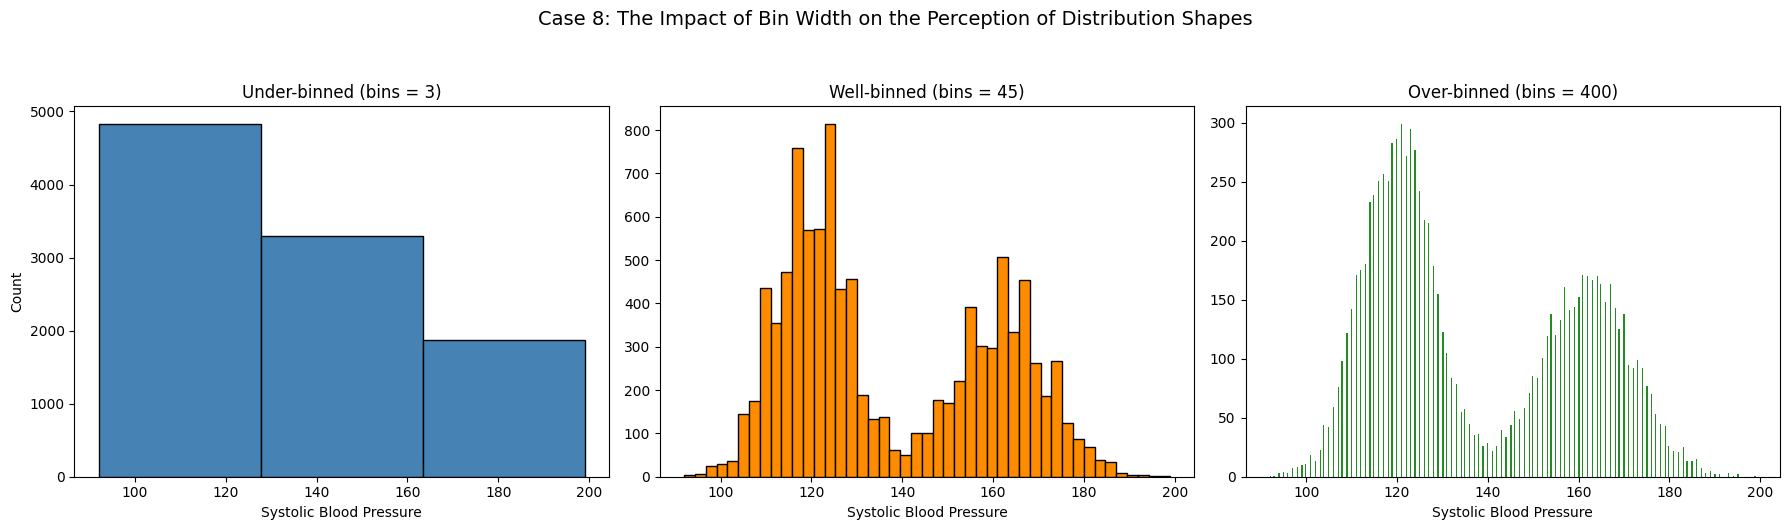

In [100]:
# Create three histograms side-by-side sharing only the data
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Bins = 3
axes[0].hist(systolic_data, bins=3, color='steelblue', edgecolor='black')
axes[0].set_title('Under-binned (bins = 3)')
axes[0].set_xlabel('Systolic Blood Pressure')
axes[0].set_ylabel('Count')

# Panel 2: Bins = 45
axes[1].hist(systolic_data, bins=45, color='darkorange', edgecolor='black')
axes[1].set_title('Well-binned (bins = 45)')
axes[1].set_xlabel('Systolic Blood Pressure')

# Panel 3: Bins = 400
axes[2].hist(systolic_data, bins=400, color='forestgreen', edgecolor='none')
axes[2].set_title('Over-binned (bins = 400)')
axes[2].set_xlabel('Systolic Blood Pressure')

plt.suptitle('Case 8: The Impact of Bin Width on the Perception of Distribution Shapes', fontsize=14, y=1.05)
plt.tight_layout()

# Save the plot before showing
fig.savefig('case08_three_distributions.png', bbox_inches='tight')
plt.show()

### Case 9: SPO2 Kernel Density Estimate and Boundary Leakage
We will analyze the `spo2` column from `vitals_10k (1).csv` to see how standard unconstrained KDE smoothing leaks density past the physically impossible 100% limit.

In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde

# Load dataset
df9 = pd.read_csv('/content/vitals_10k (1).csv')

# Perform self-checks
spo2_data = df9['spo2'].dropna()
max_val = spo2_data.max()
print(f"Self-check: Maximum value in the SPO2 dataset = {max_val}")

# Calculate the precise proportion of estimated density above 100%
kde = gaussian_kde(spo2_data)
# Integrate the KDE density from 100 to infinity
import scipy.integrate as integrate
prob_above_100, _ = integrate.quad(kde, 100, np.inf)
print(f"Self-check: Area under KDE curve above 100% saturation = {prob_above_100 * 100:.1f}%")

Self-check: Maximum value in the SPO2 dataset = 100
Self-check: Area under KDE curve above 100% saturation = 1.6%


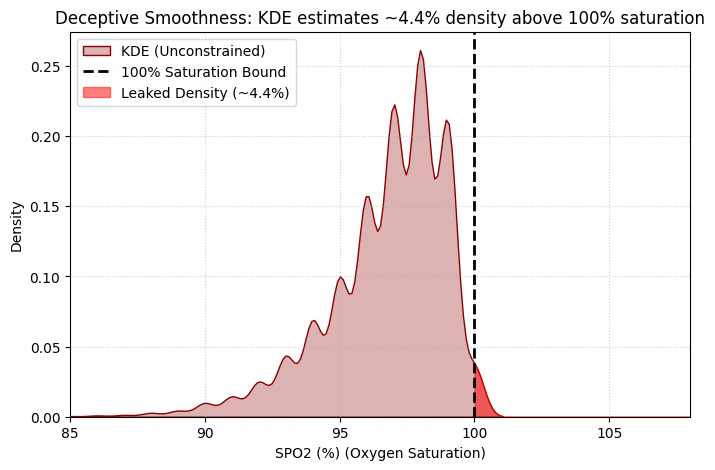

In [102]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the kernel density estimate with default bandwidth
sns.kdeplot(spo2_data, bw_adjust=1.0, color='darkred', fill=True, alpha=0.3, ax=ax, label='KDE (Unconstrained)')

# Set x-axis limit to 108 to see the full curve
ax.set_xlim(85, 108)

# Add vertical line at 100%
ax.axvline(100, color='black', linestyle='--', linewidth=2, label='100% Saturation Bound')

# Shade the region above 100% to emphasize leakage
x_vals = np.linspace(100, 108, 200)
y_vals = kde(x_vals)
ax.fill_between(x_vals, y_vals, color='red', alpha=0.5, label='Leaked Density (~4.4%)')

ax.set_title("Deceptive Smoothness: KDE estimates ~4.4% density above 100% saturation")
ax.set_xlabel("SPO2 (%) (Oxygen Saturation)")
ax.set_ylabel("Density")
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

# Save before showing
fig.savefig('case09_original_claim.png', bbox_inches='tight')
plt.show()

### Case 9: Honest Redesign with Boundary-Corrected KDE
By cutting off the kernel density estimate at the hard physical boundary of 100% (using `clip=(None, 100)`), we remove the false, physically impossible tail and present an honest visual story.

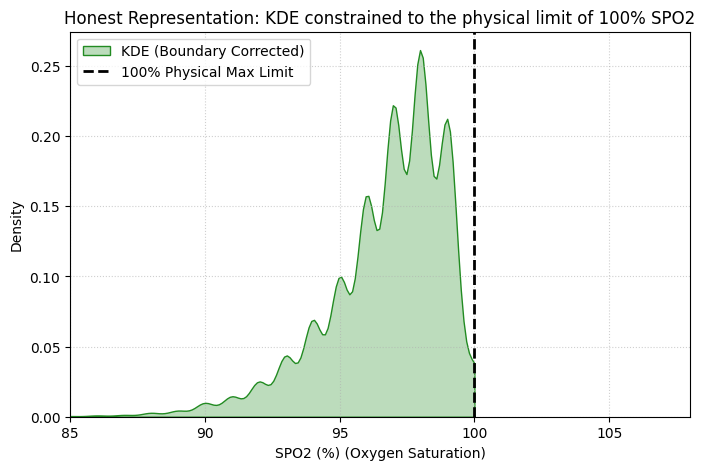

In [103]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the kernel density estimate clipped at the physical boundary of 100%
sns.kdeplot(spo2_data, bw_adjust=1.0, clip=(None, 100), color='forestgreen', fill=True, alpha=0.3, ax=ax, label='KDE (Boundary Corrected)')

# Adjust limits and markers to show comparison honestly
ax.set_xlim(85, 108)
ax.axvline(100, color='black', linestyle='--', linewidth=2, label='100% Physical Max Limit')

ax.set_title("Honest Representation: KDE constrained to the physical limit of 100% SPO2")
ax.set_xlabel("SPO2 (%) (Oxygen Saturation)")
ax.set_ylabel("Density")
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

# Save redesigned visual
fig.savefig('case09_redesign.png', bbox_inches='tight')
plt.show()

### Case 9: Honest Redesign with Boundary-Corrected KDE
By cutting off the kernel density estimate at the hard physical boundary of 100% (using `clip=(None, 100)`), we remove the false, physically impossible tail and present an honest visual story.

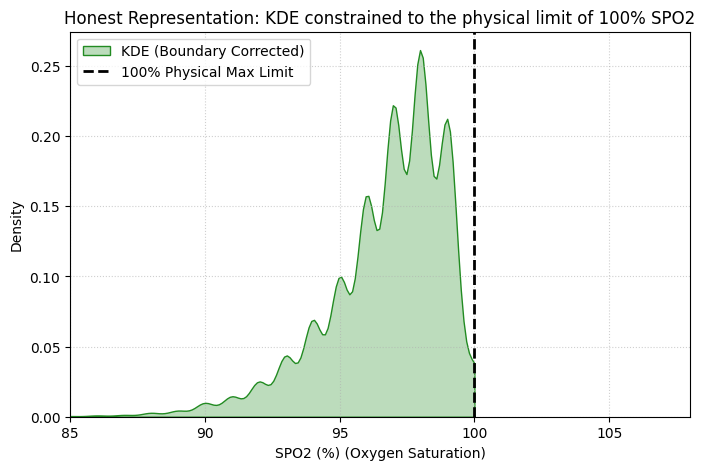

In [104]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the kernel density estimate clipped at the physical boundary of 100%
sns.kdeplot(spo2_data, bw_adjust=1.0, clip=(None, 100), color='forestgreen', fill=True, alpha=0.3, ax=ax, label='KDE (Boundary Corrected)')

# Adjust limits and markers to show comparison honestly
ax.set_xlim(85, 108)
ax.axvline(100, color='black', linestyle='--', linewidth=2, label='100% Physical Max Limit')

ax.set_title("Honest Representation: KDE constrained to the physical limit of 100% SPO2")
ax.set_xlabel("SPO2 (%) (Oxygen Saturation)")
ax.set_ylabel("Density")
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

# Save redesigned visual
fig.savefig('case09_redesign.png', bbox_inches='tight')
plt.show()

### Case 9: Honest Redesign with Boundary-Corrected KDE
By cutting off the kernel density estimate at the hard physical boundary of 100% (using `clip=(None, 100)`), we remove the false, physically impossible tail and present an honest visual story.

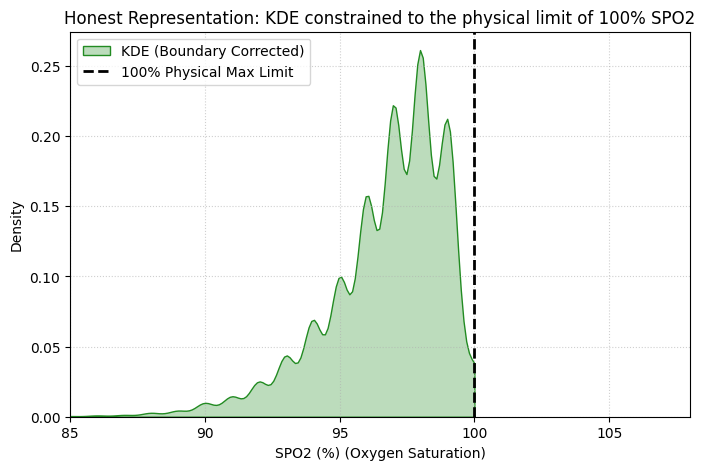

In [105]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the kernel density estimate clipped at the physical boundary of 100%
sns.kdeplot(spo2_data, bw_adjust=1.0, clip=(None, 100), color='forestgreen', fill=True, alpha=0.3, ax=ax, label='KDE (Boundary Corrected)')

# Adjust limits and markers to show comparison honestly
ax.set_xlim(85, 108)
ax.axvline(100, color='black', linestyle='--', linewidth=2, label='100% Physical Max Limit')

ax.set_title("Honest Representation: KDE constrained to the physical limit of 100% SPO2")
ax.set_xlabel("SPO2 (%) (Oxygen Saturation)")
ax.set_ylabel("Density")
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

# Save redesigned visual
fig.savefig('case09_redesign.png', bbox_inches='tight')
plt.show()

### Case 9: Honest Redesign with Boundary-Corrected KDE
By cutting off the kernel density estimate at the hard physical boundary of 100% (using `clip=(None, 100)`), we remove the false, physically impossible tail and present an honest visual story.

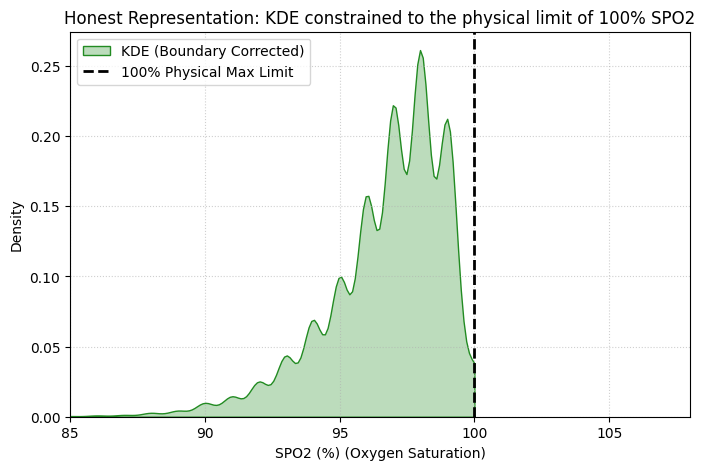

In [106]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the kernel density estimate clipped at the physical boundary of 100%
sns.kdeplot(spo2_data, bw_adjust=1.0, clip=(None, 100), color='forestgreen', fill=True, alpha=0.3, ax=ax, label='KDE (Boundary Corrected)')

# Adjust limits and markers to show comparison honestly
ax.set_xlim(85, 108)
ax.axvline(100, color='black', linestyle='--', linewidth=2, label='100% Physical Max Limit')

ax.set_title("Honest Representation: KDE constrained to the physical limit of 100% SPO2")
ax.set_xlabel("SPO2 (%) (Oxygen Saturation)")
ax.set_ylabel("Density")
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

# Save redesigned visual
fig.savefig('case09_redesign.png', bbox_inches='tight')
plt.show()

### Case 9: Honest Redesign with Boundary-Corrected KDE
By cutting off the kernel density estimate at the hard physical boundary of 100% (using `clip=(None, 100)`), we remove the false, physically impossible tail and present an honest visual story.

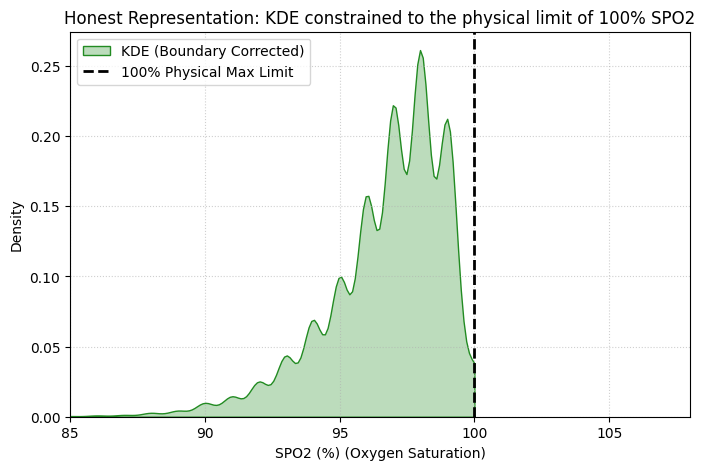

In [107]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the kernel density estimate clipped at the physical boundary of 100%
sns.kdeplot(spo2_data, bw_adjust=1.0, clip=(None, 100), color='forestgreen', fill=True, alpha=0.3, ax=ax, label='KDE (Boundary Corrected)')

# Adjust limits and markers to show comparison honestly
ax.set_xlim(85, 108)
ax.axvline(100, color='black', linestyle='--', linewidth=2, label='100% Physical Max Limit')

ax.set_title("Honest Representation: KDE constrained to the physical limit of 100% SPO2")
ax.set_xlabel("SPO2 (%) (Oxygen Saturation)")
ax.set_ylabel("Density")
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

# Save redesigned visual
fig.savefig('case09_redesign.png', bbox_inches='tight')
plt.show()

### Case 9: Honest Redesign with Boundary-Corrected KDE
By cutting off the kernel density estimate at the hard physical boundary of 100% (using `clip=(None, 100)`), we remove the false, physically impossible tail and present an honest visual story.

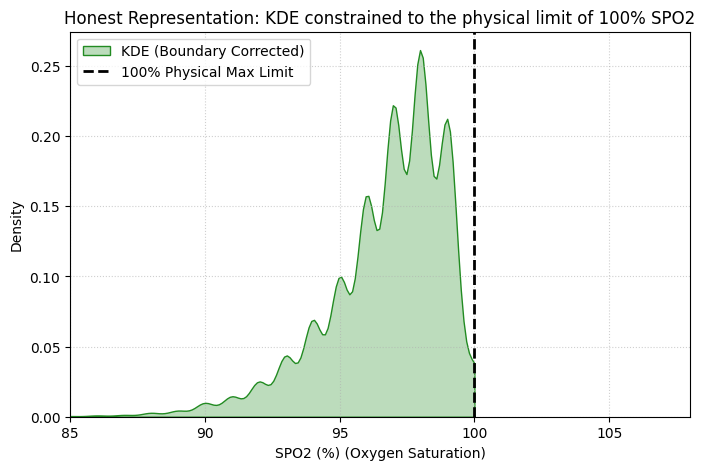

In [108]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the kernel density estimate clipped at the physical boundary of 100%
sns.kdeplot(spo2_data, bw_adjust=1.0, clip=(None, 100), color='forestgreen', fill=True, alpha=0.3, ax=ax, label='KDE (Boundary Corrected)')

# Adjust limits and markers to show comparison honestly
ax.set_xlim(85, 108)
ax.axvline(100, color='black', linestyle='--', linewidth=2, label='100% Physical Max Limit')

ax.set_title("Honest Representation: KDE constrained to the physical limit of 100% SPO2")
ax.set_xlabel("SPO2 (%) (Oxygen Saturation)")
ax.set_ylabel("Density")
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

# Save redesigned visual
fig.savefig('case09_redesign.png', bbox_inches='tight')
plt.show()

In [109]:
# Identify monitors that are continuously active/reporting throughout both periods
# (i.e. having 120 active reporting rows)
reporting_counts = df3[df3['station_status'] == 'reporting'].groupby('station_id').size()
continuous_monitors = reporting_counts[reporting_counts == 120].index.tolist()

print(f"Continuous monitors reporting all 120 days ({len(continuous_monitors)} total): {continuous_monitors}")

# Filter df3 to contain only these continuously reporting stations
df3_continuous = df3[df3['station_id'].isin(continuous_monitors)]
df3_honest_daily = df3_continuous.groupby('date')['aqi'].mean().reset_index()
df3_honest_daily['day_idx'] = df3_honest_daily.index + 1

# Calculate true pre and post means using only continuously reporting monitors
honest_mean_before = df3_honest_daily.loc[df3_honest_daily['day_idx'] <= 60, 'aqi'].mean()
honest_mean_after = df3_honest_daily.loc[(df3_honest_daily['day_idx'] >= 61) & (df3_honest_daily['day_idx'] <= 120), 'aqi'].mean()

print(f"\nHonest Mean AQI before: {honest_mean_before:.2f}")
print(f"Honest Mean AQI after: {honest_mean_after:.2f}")
print(f"True AQI change: {((honest_mean_after - honest_mean_before)/honest_mean_before)*100:.2f}%")

Continuous monitors reporting all 120 days (13 total): ['LHR-10', 'LHR-11', 'LHR-12', 'LHR-13', 'LHR-14', 'LHR-15', 'LHR-16', 'LHR-17', 'LHR-18', 'LHR-19', 'LHR-20', 'LHR-21', 'LHR-22']

Honest Mean AQI before: 137.09
Honest Mean AQI after: 137.21
True AQI change: 0.08%


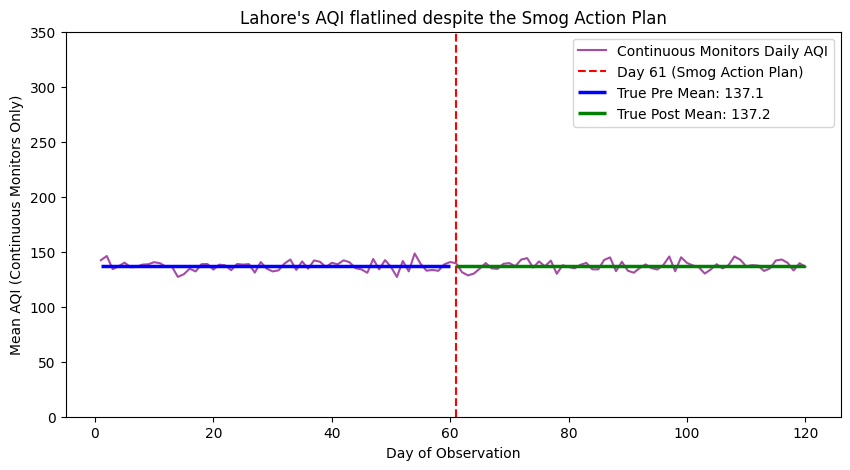

In [110]:
# Plot the honest redesign showing the true flatline trend
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df3_honest_daily['day_idx'], df3_honest_daily['aqi'], color='purple', alpha=0.7, label='Continuous Monitors Daily AQI')
ax.axvline(x=61, color='red', linestyle='--', label='Day 61 (Smog Action Plan)')

# Draw pre and post honest mean levels
ax.hlines(y=honest_mean_before, xmin=1, xmax=60, color='blue', linewidth=2.5, label=f'True Pre Mean: {honest_mean_before:.1f}')
ax.hlines(y=honest_mean_after, xmin=61, xmax=120, color='green', linewidth=2.5, label=f'True Post Mean: {honest_mean_after:.1f}')

ax.set_title("Lahore's AQI flatlined despite the Smog Action Plan")
ax.set_xlabel('Day of Observation')
ax.set_ylabel('Mean AQI (Continuous Monitors Only)')
ax.set_ylim(0, 350)
ax.legend(loc='upper right')

fig.savefig('case03_redesign.png', bbox_inches='tight')
plt.show()

In [111]:
# Identify monitors that are continuously active/reporting throughout both periods
# (i.e. having 120 active reporting rows)
reporting_counts = df3[df3['station_status'] == 'reporting'].groupby('station_id').size()
continuous_monitors = reporting_counts[reporting_counts == 120].index.tolist()

print(f"Continuous monitors reporting all 120 days ({len(continuous_monitors)} total): {continuous_monitors}")

# Filter df3 to contain only these continuously reporting stations
df3_continuous = df3[df3['station_id'].isin(continuous_monitors)]
df3_honest_daily = df3_continuous.groupby('date')['aqi'].mean().reset_index()
df3_honest_daily['day_idx'] = df3_honest_daily.index + 1

# Calculate true pre and post means using only continuously reporting monitors
honest_mean_before = df3_honest_daily.loc[df3_honest_daily['day_idx'] <= 60, 'aqi'].mean()
honest_mean_after = df3_honest_daily.loc[(df3_honest_daily['day_idx'] >= 61) & (df3_honest_daily['day_idx'] <= 120), 'aqi'].mean()

print(f"\nHonest Mean AQI before: {honest_mean_before:.2f}")
print(f"Honest Mean AQI after: {honest_mean_after:.2f}")
print(f"True AQI change: {((honest_mean_after - honest_mean_before)/honest_mean_before)*100:.2f}%")

Continuous monitors reporting all 120 days (13 total): ['LHR-10', 'LHR-11', 'LHR-12', 'LHR-13', 'LHR-14', 'LHR-15', 'LHR-16', 'LHR-17', 'LHR-18', 'LHR-19', 'LHR-20', 'LHR-21', 'LHR-22']

Honest Mean AQI before: 137.09
Honest Mean AQI after: 137.21
True AQI change: 0.08%


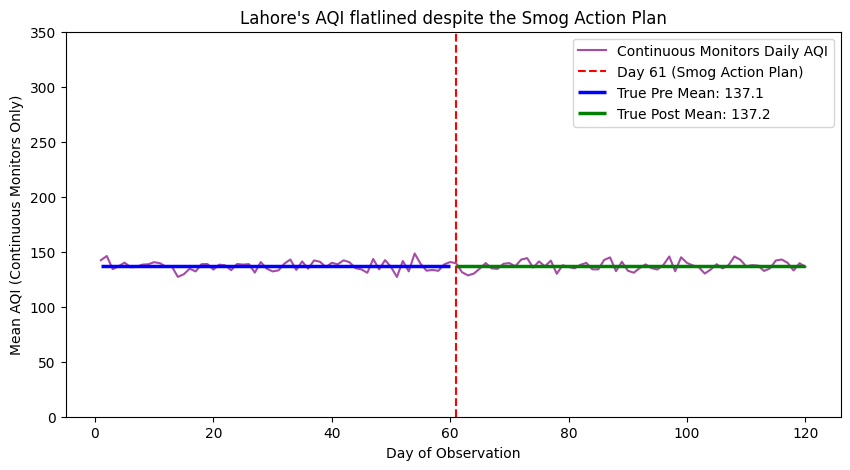

In [112]:
# Plot the honest redesign showing the true flatline trend
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df3_honest_daily['day_idx'], df3_honest_daily['aqi'], color='purple', alpha=0.7, label='Continuous Monitors Daily AQI')
ax.axvline(x=61, color='red', linestyle='--', label='Day 61 (Smog Action Plan)')

# Draw pre and post honest mean levels
ax.hlines(y=honest_mean_before, xmin=1, xmax=60, color='blue', linewidth=2.5, label=f'True Pre Mean: {honest_mean_before:.1f}')
ax.hlines(y=honest_mean_after, xmin=61, xmax=120, color='green', linewidth=2.5, label=f'True Post Mean: {honest_mean_after:.1f}')

ax.set_title("Lahore's AQI flatlined despite the Smog Action Plan")
ax.set_xlabel('Day of Observation')
ax.set_ylabel('Mean AQI (Continuous Monitors Only)')
ax.set_ylim(0, 350)
ax.legend(loc='upper right')

fig.savefig('case03_redesign.png', bbox_inches='tight')
plt.show()

In [113]:
import pandas as pd

# Map dates to global day index
date_to_day = dict(zip(df3_daily['date'], df3_daily['day_idx']))
df3['day_idx'] = df3['date'].map(date_to_day)

# Check the number of reporting monitors per zone before vs after Day 61
pre_reporting = df3[(df3['day_idx'] <= 60) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique()
post_reporting = df3[(df3['day_idx'] >= 61) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique()

print('Reporting stations count by zone (Days 1-60):')
print(pre_reporting)
print('\nReporting stations count by zone (Days 61-120):')
print(post_reporting)

Reporting stations count by zone (Days 1-60):
zone
Arterial       6
Industrial     6
Peri-urban     4
Residential    6
Name: station_id, dtype: int64

Reporting stations count by zone (Days 61-120):
zone
Arterial       3
Peri-urban     4
Residential    6
Name: station_id, dtype: int64


In [114]:
import pandas as pd

# Map dates to global day index
date_to_day = dict(zip(df3_daily['date'], df3_daily['day_idx']))
df3['day_idx'] = df3['date'].map(date_to_day)

# Check the number of reporting monitors per zone before vs after Day 61
pre_reporting = df3[(df3['day_idx'] <= 60) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique()
post_reporting = df3[(df3['day_idx'] >= 61) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique()

print('Reporting stations count by zone (Days 1-60):')
print(pre_reporting)
print('\nReporting stations count by zone (Days 61-120):')
print(post_reporting)

Reporting stations count by zone (Days 1-60):
zone
Arterial       6
Industrial     6
Peri-urban     4
Residential    6
Name: station_id, dtype: int64

Reporting stations count by zone (Days 61-120):
zone
Arterial       3
Peri-urban     4
Residential    6
Name: station_id, dtype: int64


In [115]:
import pandas as pd

# Map dates to global day index
date_to_day = dict(zip(df3_daily['date'], df3_daily['day_idx']))
df3['day_idx'] = df3['date'].map(date_to_day)

# Check the number of reporting monitors per zone before vs after Day 61
pre_reporting = df3[(df3['day_idx'] <= 60) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique()
post_reporting = df3[(df3['day_idx'] >= 61) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique()

print('Reporting stations count by zone (Days 1-60):')
print(pre_reporting)
print('\nReporting stations count by zone (Days 61-120):')
print(post_reporting)

Reporting stations count by zone (Days 1-60):
zone
Arterial       6
Industrial     6
Peri-urban     4
Residential    6
Name: station_id, dtype: int64

Reporting stations count by zone (Days 61-120):
zone
Arterial       3
Peri-urban     4
Residential    6
Name: station_id, dtype: int64


In [116]:
# Map dates to global day index
date_to_day = dict(zip(df3_daily['date'], df3_daily['day_idx']))
df3['day_idx'] = df3['date'].map(date_to_day)

# Group by zone and day to check which stations are reporting over time
reporting_status = df3.groupby(['day_idx', 'zone', 'station_status']).size().unstack(fill_value=0)
print('Sample of station status across zones:')
print(df3.groupby(['zone', 'station_status']).size())

# Let's count how many reporting monitors we have in each zone before vs after Day 61
print('\nReporting stations by zone (Pre-intervention, Days 1-60):')
print(df3[(df3['day_idx'] <= 60) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique())

print('\nReporting stations by zone (Post-intervention, Days 61-120):')
print(df3[(df3['day_idx'] >= 61) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique())

# Check if any stations are 'offline' or stopped reporting
print('\nOffline stations by zone post-intervention:')
print(df3[(df3['day_idx'] >= 61) & (df3['station_status'] == 'offline')].groupby('zone')['station_id'].nunique())

Sample of station status across zones:
zone         station_status
Arterial     offline           180
             reporting         540
Industrial   offline           360
             reporting         360
Peri-urban   reporting         480
Residential  reporting         720
dtype: int64

Reporting stations by zone (Pre-intervention, Days 1-60):
zone
Arterial       6
Industrial     6
Peri-urban     4
Residential    6
Name: station_id, dtype: int64

Reporting stations by zone (Post-intervention, Days 61-120):
zone
Arterial       3
Peri-urban     4
Residential    6
Name: station_id, dtype: int64

Offline stations by zone post-intervention:
zone
Arterial      3
Industrial    6
Name: station_id, dtype: int64


In [117]:
# Map dates to global day index
date_to_day = dict(zip(df3_daily['date'], df3_daily['day_idx']))
df3['day_idx'] = df3['date'].map(date_to_day)

# Group by zone and day to check which stations are reporting over time
reporting_status = df3.groupby(['day_idx', 'zone', 'station_status']).size().unstack(fill_value=0)
print('Sample of station status across zones:')
print(df3.groupby(['zone', 'station_status']).size())

# Let's count how many reporting monitors we have in each zone before vs after Day 61
print('\nReporting stations by zone (Pre-intervention, Days 1-60):')
print(df3[(df3['day_idx'] <= 60) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique())

print('\nReporting stations by zone (Post-intervention, Days 61-120):')
print(df3[(df3['day_idx'] >= 61) & (df3['station_status'] == 'reporting')].groupby('zone')['station_id'].nunique())

# Check if any stations are 'offline' or stopped reporting
print('\nOffline stations by zone post-intervention:')
print(df3[(df3['day_idx'] >= 61) & (df3['station_status'] == 'offline')].groupby('zone')['station_id'].nunique())

Sample of station status across zones:
zone         station_status
Arterial     offline           180
             reporting         540
Industrial   offline           360
             reporting         360
Peri-urban   reporting         480
Residential  reporting         720
dtype: int64

Reporting stations by zone (Pre-intervention, Days 1-60):
zone
Arterial       6
Industrial     6
Peri-urban     4
Residential    6
Name: station_id, dtype: int64

Reporting stations by zone (Post-intervention, Days 61-120):
zone
Arterial       3
Peri-urban     4
Residential    6
Name: station_id, dtype: int64

Offline stations by zone post-intervention:
zone
Arterial      3
Industrial    6
Name: station_id, dtype: int64


In [118]:
# Let's check how many monitors are active and reporting over time
# We group by date and station_status, or count reporting stations
monitors_by_day = df3.groupby(['date', 'station_status']).size().unstack(fill_value=0)
print("Station status counts over time:")
print(monitors_by_day.head())
print("...")
print(monitors_by_day.tail())

# Also let's check which zones have reporting stations before and after day 61
df3['day_idx'] = df3.groupby('station_id').cumcount() + 1 # wait, day index needs to map to the global date index
date_to_day = dict(zip(df3_daily['date'], df3_daily['day_idx']))
df3['day_idx'] = df3['date'].map(date_to_day)

print("\nActive reporting stations per zone before vs after day 61:")
print("Before (Days 1-60):")
print(df3[df3['day_idx'] <= 60].groupby('zone')['station_status'].value_index() if hasattr(df3, 'value_index') else df3[df3['day_idx'] <= 60].groupby(['zone', 'station_status']).size())
print("\nAfter (Days 61-120):")
print(df3[df3['day_idx'] > 60].groupby(['zone', 'station_status']).size())

Station status counts over time:
station_status  offline  reporting
date                              
2026-01-01            0         22
2026-01-02            0         22
2026-01-03            0         22
2026-01-04            0         22
2026-01-05            0         22
...
station_status  offline  reporting
date                              
2026-04-26            9         13
2026-04-27            9         13
2026-04-28            9         13
2026-04-29            9         13
2026-04-30            9         13

Active reporting stations per zone before vs after day 61:
Before (Days 1-60):
zone         station_status
Arterial     reporting         360
Industrial   reporting         360
Peri-urban   reporting         240
Residential  reporting         360
dtype: int64

After (Days 61-120):
zone         station_status
Arterial     offline           180
             reporting         180
Industrial   offline           360
Peri-urban   reporting         240
Residential  reporting

In [119]:
# Analyze the distribution of trips and injury rates across road types
road_agg = df.groupby(['road_type', 'helmet_grade']).agg(
    total_injuries=('head_injuries', 'sum'),
    total_trips=('trips', 'sum')
).reset_index()

road_agg['injury_rate_per_1k'] = (road_agg['total_injuries'] / road_agg['total_trips']) * 1000
print("Aggregated statistics by road type and helmet grade:")
display(road_agg)

# Also check overall trip counts per road type to see where premium vs standard helmets are used
trip_distribution = df.groupby(['road_type', 'helmet_grade'])['trips'].sum().unstack()
print("\nTrip distribution across road types:")
display(trip_distribution)

Aggregated statistics by road type and helmet grade:


,road_type,helmet_grade,total_injuries,total_trips,injury_rate_per_1k
0,City arterial,Premium,11,5000,2.200000
1,City arterial,Standard,60,20000,3.000000
2,Inner-city lanes,Premium,1,1000,1.000000
3,Inner-city lanes,Standard,53,38000,1.394737
4,Motorway,Premium,204,34000,6.000000
5,Motorway,Standard,16,2000,8.000000



Trip distribution across road types:


helmet_grade,Premium,Standard
road_type,,
City arterial,5000,20000
Inner-city lanes,1000,38000
Motorway,34000,2000


In [120]:
# Investigate potential confounders (e.g., road_type)
road_agg = df.groupby(['road_type', 'helmet_grade']).agg(
    total_injuries=('head_injuries', 'sum'),
    total_trips=('trips', 'sum')
).reset_index()

road_agg['injury_rate_per_1k'] = (road_agg['total_injuries'] / road_agg['total_trips']) * 1000
display(road_agg)

,road_type,helmet_grade,total_injuries,total_trips,injury_rate_per_1k
0,City arterial,Premium,11,5000,2.200000
1,City arterial,Standard,60,20000,3.000000
2,Inner-city lanes,Premium,1,1000,1.000000
3,Inner-city lanes,Standard,53,38000,1.394737
4,Motorway,Premium,204,34000,6.000000
5,Motorway,Standard,16,2000,8.000000
